# Table of Contents
- 1. Formulating Hypotheses from Visualizations
- 2. Segment-Based Deep Dives (Slicing and Dicing)
- 3. Identifying Confounders and Simpson’s Paradox in EDA
- 4. Translating Findings into Actionable Insights

In [6]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for EDA story extraction framework loaded successfully.")

Global libraries for EDA story extraction framework loaded successfully.


In [ ]:
import numpy as np
import scipy.stats as stats
np.random.seed(42)
# Group 1: Students who drank coffee (higher average score)
coffee_scores = np.random.normal(loc=82, scale=6, size=30)
# Group 2: Students who didn't drink coffee (lower average score)
no_coffee_scores = np.random.normal(loc=76, scale=7, size=30)

# 2. Run the Independent Two-Sample t-test
t_stat, p_value = stats.ttest_ind(coffee_scores, no_coffee_scores)

# 3. Print the results
print(f"Mean Coffee Score: {np.mean(coffee_scores):.2f}")
print(f"Mean No-Coffee Score: {np.mean(no_coffee_scores):.2f}")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4f}")

# 4. Make a statistical decision using the standard alpha threshold of 0.05
# It represents your tolerance for false positives (technically called a Type I error).
alpha = 0.05 # significance level or alpha level.
# 4. Make a statistical decision using the standard alpha threshold of 0.05
alpha = 0.05
if p_value < alpha:
    print("\nResult: Reject the Null Hypothesis (H0). The difference in test scores is statistically significant!")
else:
    print("\nResult: Fail to Reject the Null Hypothesis (H0). Any difference could easily be due to random chance.")

Observed Conversion Rates by Hypothesis Segment:
     device  conversion
0  Desktop        0.15
1   Mobile        0.05


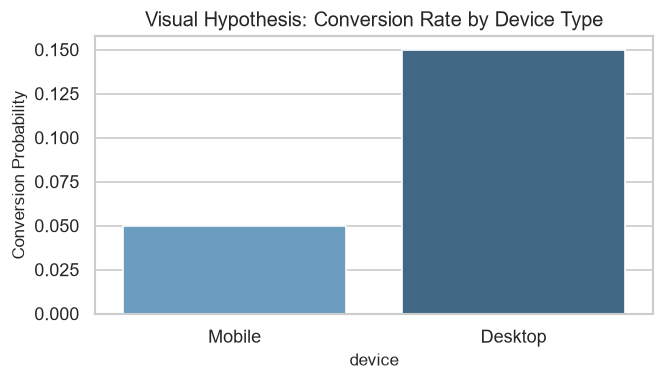

In [7]:
import pandas as pd
np.random.seed(42)
df_hyp = pd.DataFrame({
    'device': ['Mobile'] * 100 + ['Desktop'] * 100,
    'conversion': np.concatenate([np.random.binomial(1, 0.05, 100), np.random.binomial(1, 0.12, 100)])
})
# print(df_hyp)

conversion_rates = df_hyp.groupby('device')['conversion'].mean().reset_index()
print("Observed Conversion Rates by Hypothesis Segment:\n", conversion_rates)

# Visualization
plt.figure(figsize=(6, 3))
sns.barplot(x='device', y='conversion', hue='device', data=df_hyp, palette='Blues_d', legend=False, errorbar=None)
plt.title('Visual Hypothesis: Conversion Rate by Device Type')
plt.ylabel('Conversion Probability')
plt.show()

## 2. Segment-Based Deep Dives (Slicing and Dicing)

Segment Deep-Dive Summary:
 region      North  South
tier                    
Enterprise   0.01   0.02
Free         0.25   0.28
Pro          0.05   0.04


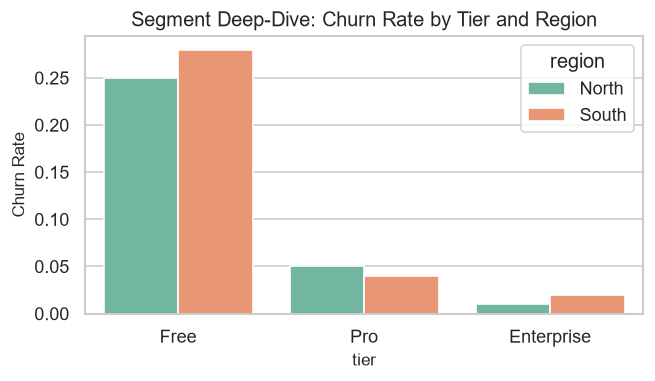

In [9]:
df_seg = pd.DataFrame({
    'tier': ['Free', 'Free', 'Pro', 'Pro', 'Enterprise', 'Enterprise'],
    'region': ['North', 'South', 'North', 'South', 'North', 'South'],
    'churn_rate': [0.25, 0.28, 0.05, 0.04, 0.01, 0.02]
})

print(
    "Segment Deep-Dive Summary:\n",
    df_seg.pivot(index='tier', columns='region', values='churn_rate'),
)
# Visualization
plt.figure(figsize=(6, 3))
sns.barplot(x='tier', y='churn_rate', hue='region', data=df_seg, palette='Set2', errorbar=None)
plt.title('Segment Deep-Dive: Churn Rate by Tier and Region')
plt.ylabel('Churn Rate')
plt.show()

## 3. Identifying Confounders and Simpson’s Paradox in EDA


### 1. Definition
Simpson's Paradox occurs when a trend appearing in different groups of data reverses or disappears when groups are combined, caused by a hidden confounding variable associated with both the independent and dependent variables.


### 4. Naive Example
A medical treatment appears less effective overall because it is disproportionately administered to severe cases, but proves superior when evaluated within each specific severity tier.

### 5. Uses
- Preventing false causal inferences and flawed executive conclusions during exploratory analysis.
- Identifying omitted variables that distort model coefficients.
- Ensuring proper stratification during data splitting and experiment design.

Simpson's Paradox Dataset Head:
           x         y    group
0  1.000000  8.099343  Group A
1  1.081633  7.890714  Group A
2  1.163265  7.966272  Group A


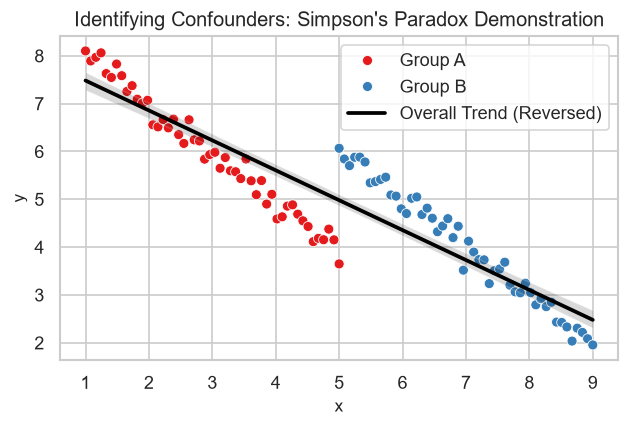

In [11]:
np.random.seed(42)
n = 100
x_simpson = np.concatenate([np.linspace(1, 5, 50), np.linspace(5, 9, 50)])
y_simpson = np.concatenate([np.linspace(8, 4, 50), np.linspace(6, 2, 50)]) + np.random.normal(0, 0.2, 100)
group = ['Group A']*50 + ['Group B']*50

df_simp = pd.DataFrame({'x': x_simpson, 'y': y_simpson, 'group': group})
print("Simpson's Paradox Dataset Head:\n", df_simp.head(3))

# Visualization
plt.figure(figsize=(6, 3.5))
sns.scatterplot(x='x', y='y', hue='group', data=df_simp, palette='Set1')
sns.regplot(x='x', y='y', data=df_simp, scatter=False, color='black', label='Overall Trend (Reversed)')
plt.title("Identifying Confounders: Simpson's Paradox Demonstration")
plt.legend()
plt.show()